# SmartCart – E-commerce Customer Segmentation System

Customer segmentation using exploratory data analysis, feature engineering, PCA, and clustering.

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv("smartcart_customers.csv")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [3]:
df.shape

(2240, 22)

In [4]:
# Check missing values
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

The `Income` column contains 24 missing values.

#### Data Preprocessing

##### 1. Handling Missing Values

In [5]:
df["Income"] = df["Income"].fillna(df["Income"].median())


In [6]:
df.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

After handling missing values, no null values remain in the dataset.

##### 2. Feature Engineering

Create useful features for customer profiling and remove columns that do not help segmentation.

We derive more useful features from `Year_Birth` and `Dt_Customer`, then combine product-level spending into an overall spending feature.

The `Age` feature can help compare purchasing patterns across age groups.

In [7]:
# Create Age feature
df["Age"] = 2026 - df["Year_Birth"]

In [8]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,88,88,3,8,10,4,7,0,1,69
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,1,6,2,1,1,2,5,0,0,72
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,21,42,1,8,2,10,4,0,0,61
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,3,5,2,2,0,4,6,0,0,42
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,27,15,5,5,3,6,5,0,0,45


Convert `Dt_Customer` into `Customer_Tenure_Days`, the number of days between a customer's joining date and a fixed reference date.

The dates are parsed with `dayfirst=True` because they use the day-month-year format.

Using the latest joining date in the dataset as the reference keeps tenure values reproducible across runs.

In [9]:
# Interpret dates as DD-MM-YYYY.
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True)

reference_date = df["Dt_Customer"].max()

df["Customer_Tenure_Days"] = (reference_date - df["Dt_Customer"]).dt.days

In [10]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


Combine product spending columns into `Total_Spending` to represent each customer's overall spending.

In [11]:
# Create Total_Spending feature
df["Total_Spending"]= df["MntWines"] + df["MntFruits"] + df["MntMeatProducts"] + df["MntFishProducts"] + df["MntSweetProducts"] + df["MntGoldProds"]

In [12]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,3,8,10,4,7,0,1,69,663,1617
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,2,1,1,2,5,0,0,72,113,27
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,1,8,2,10,4,0,0,61,312,776
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,2,0,4,6,0,0,42,139,53
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,5,3,6,5,0,0,45,161,422


`Total_Children` combines `Kidhome` and `Teenhome` to represent the number of children and teenagers in the household.

In [13]:
# Create Total_Children feature
df["Total_Children"] = df["Kidhome"] + df["Teenhome"]

In [14]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,8,10,4,7,0,1,69,663,1617,0
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,1,2,5,0,0,72,113,27,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,8,2,10,4,0,0,61,312,776,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,2,0,4,6,0,0,42,139,53,1
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,3,6,5,0,0,45,161,422,1


In [15]:
# Check education categories
df["Education"].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

Group education into three categories:

- **Undergraduate:** `2n Cycle`, `Basic`
- **Graduate:** `Graduation`
- **Postgraduate:** `PhD`, `Master`

In [16]:
df["Education"] = df["Education"].replace({
    "Basic" : "Undergraduate","2n Cycle" : "Undergraduate",
    "Graduation" : "Graduate",
    "PhD" : "Postgraduate","Master": "Postgraduate"
})

In [17]:
df["Education"].value_counts()

Education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64

In [18]:
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

Create `Living_With`: map `Married` and `Together` to `Partner`, and the remaining categories to `Alone`. This is a simplified grouping based on marital-status values, not a confirmed household arrangement.

In [19]:
# Group marital status into living categories
df["Living_With"] = df["Marital_Status"].replace({
    "Married" : "Partner", "Together":"Partner",
    "Single" : "Alone","Divorced" : "Alone","Widow" : "Alone",
    "Alone" : "Alone","Absurd" : "Alone","YOLO" : "Alone"
})

In [20]:
df["Living_With"].value_counts()

Living_With
Partner    1444
Alone       796
Name: count, dtype: int64

In [21]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,5524,1957,Graduate,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1617,0,Alone
1,2174,1954,Graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,27,2,Alone
2,4141,1965,Graduate,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,776,0,Partner
3,6182,1984,Graduate,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,53,1,Partner
4,5324,1981,Postgraduate,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,422,1,Partner


##### 3. Remove Unnecessary Columns

In [22]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,5524,1957,Graduate,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1617,0,Alone
1,2174,1954,Graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,27,2,Alone
2,4141,1965,Graduate,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,776,0,Partner
3,6182,1984,Graduate,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,53,1,Partner
4,5324,1981,Postgraduate,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,422,1,Partner


In [23]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure_Days', 'Total_Spending',
       'Total_Children', 'Living_With'],
      dtype='object')

Drop `ID` because it identifies each customer but does not describe purchasing behavior.

Remove `ID`, the original columns replaced by engineered features, and the individual product-spending columns represented by `Total_Spending`.

In [24]:
cols=["ID", "Year_Birth", "Marital_Status", "Kidhome", "Teenhome", "Dt_Customer"]
spending_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

cols_to_drop = cols + spending_cols

df_cleaned = df.drop(columns= cols_to_drop)


In [25]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


In [26]:
df_cleaned.shape

(2240, 15)

The dataset grew from 22 to 27 columns after feature engineering. After removing unnecessary columns, 15 columns remain for analysis.

##### 4. Handle Outliers

A pair plot helps compare numerical features and spot unusual values.

In a pair plot, the diagonal shows each feature's distribution, while the other panels show relationships between pairs of features.

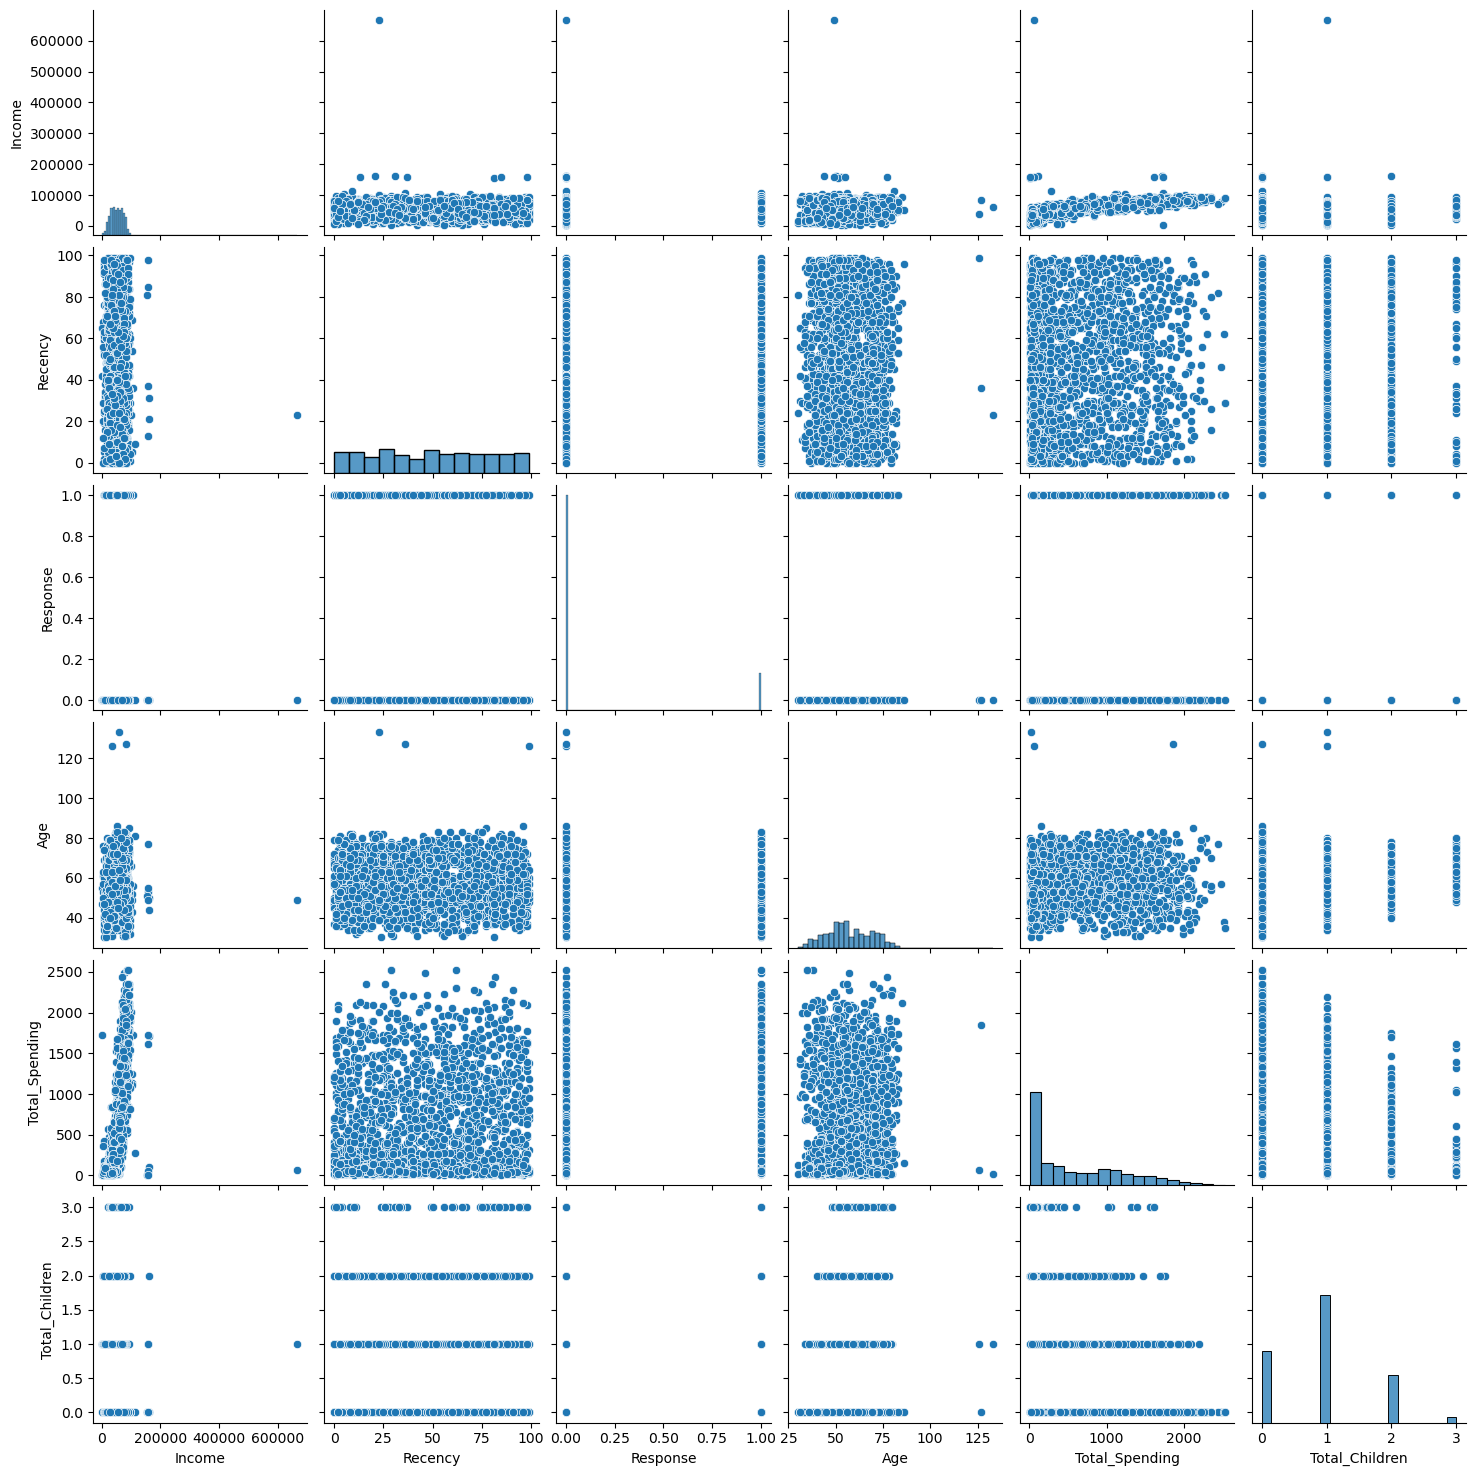

In [27]:
cols=["Income", "Recency", "Response", "Age", "Total_Spending", "Total_Children"]


sns.pairplot(df_cleaned[cols])

The plots show a very high-income observation and some unusually high ages. For this analysis, filter the data to `Age < 90` and `Income < 600000` before clustering.

In [28]:
# Remove outliers using the selected age and income limits
print("Data size before removing outliers:", len(df_cleaned))

# Keep customers younger than 90.
df_cleaned = df_cleaned[df_cleaned["Age"] < 90]

# Keep customers with income below 600,000.
df_cleaned = df_cleaned[df_cleaned["Income"] < 600_000]

print("Data size after removing outliers:", len(df_cleaned))

Data size before removing outliers: 2240
Data size after removing outliers: 2236


Four rows were removed by the selected filters.

The filtered dataset is stored in `df_cleaned`.

##### 5. Correlation Heatmap

In [29]:

corr = df_cleaned.corr(numeric_only=True) 
corr

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children
Income,1.000000,0.007829,-0.107169,0.450584,0.693781,0.628075,-0.646382,-0.027871,0.161121,0.198835,-0.023677,0.789375,-0.340550
Recency,0.007829,1.000000,-0.000638,-0.010776,0.025226,0.000771,-0.021850,0.005361,-0.198781,0.019396,0.024238,0.020842,0.017826
NumDealsPurchases,-0.107169,-0.000638,1.000000,0.233971,-0.008510,0.068418,0.347216,0.003636,0.002017,0.068286,0.218009,-0.064831,0.439682
NumWebPurchases,0.450584,-0.010776,0.233971,1.000000,0.378049,0.502227,-0.056204,-0.013250,0.148390,0.153873,0.191211,0.519948,-0.146429
NumCatalogPurchases,0.693781,0.025226,-0.008510,0.378049,1.000000,0.518788,-0.520376,-0.018304,0.220813,0.125285,0.095836,0.778343,-0.439631
NumStorePurchases,0.628075,0.000771,0.068418,0.502227,0.518788,1.000000,-0.429857,-0.011563,0.038702,0.139237,0.109727,0.675460,-0.321729
NumWebVisitsMonth,-0.646382,-0.021850,0.347216,-0.056204,-0.520376,-0.429857,1.000000,0.020796,-0.004397,-0.117498,0.272105,-0.499909,0.417908
Complain,-0.027871,0.005361,0.003636,-0.013250,-0.018304,-0.011563,0.020796,1.000000,0.000167,0.004450,0.035685,-0.033784,0.031480
Response,0.161121,-0.198781,0.002017,0.148390,0.220813,0.038702,-0.004397,0.000167,1.000000,-0.018557,0.194232,0.265615,-0.169451
Age,0.198835,0.019396,0.068286,0.153873,0.125285,0.139237,-0.117498,0.004450,-0.018557,1.000000,-0.016451,0.113618,0.095512


<Axes: >

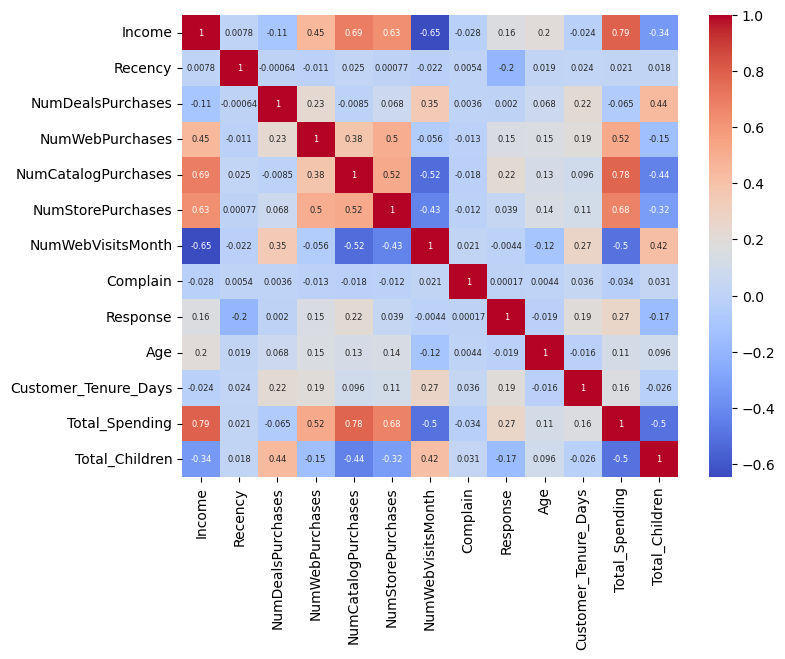

In [30]:

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,  
    annot_kws={"size": 6},  
    cmap="coolwarm"  
)

### Key correlation findings

- `Income` and `Total_Spending`: **0.79** (strong positive correlation).
- `Income` and `NumCatalogPurchases`: **0.69** (positive).
- `Income` and `NumStorePurchases`: **0.63** (positive).
- `Income` and `NumWebVisitsMonth`: **-0.65** (negative).
- `Total_Spending` and `NumCatalogPurchases`: **0.78** (strong positive).
- `NumStorePurchases` and `NumWebVisitsMonth`: **-0.43** (moderate negative).

These are correlations and do not establish cause and effect.

In [31]:
df_cleaned.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,Postgraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


##### 6. Feature Encoding

In [32]:
from sklearn.preprocessing import OneHotEncoder


In [33]:
ohe = OneHotEncoder()

cat_cols = ["Education", "Living_With"]

enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

Convert the One-Hot Encoder output into a pandas DataFrame so it can be combined with the other features.

In [34]:
enc_df = pd.DataFrame(enc_cols.toarray(), columns=ohe.get_feature_names_out(cat_cols), index=df_cleaned.index)

In [35]:
enc_df.head()

,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


We retain all one-hot encoded columns. Unlike some linear-model workflows, dropping a category is not automatically required for clustering; it can change distances between customers and therefore affect cluster results.

Combine the encoded categorical features with the remaining dataset using `pd.concat()`.

In [36]:
df_encoded = pd.concat([df_cleaned.drop(columns = cat_cols), enc_df ], axis = 1)

In [37]:
df_encoded.shape

(2236, 18)

In [38]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


##### 7. Data Scaling / Standardizing data

In [39]:

X= df_encoded

In [40]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

##### 8. Visualization

In [41]:
X_scaled.shape

(2236, 18)

The data has 18 features, so it cannot be shown directly in a 2D plot. Use PCA to create lower-dimensional visualizations.

In [42]:
from sklearn.decomposition import PCA


### 2D PCA visualization

In [43]:
pca = PCA(
    n_components = 2
)

X_pca = pca.fit_transform(X_scaled)

<Axes: >

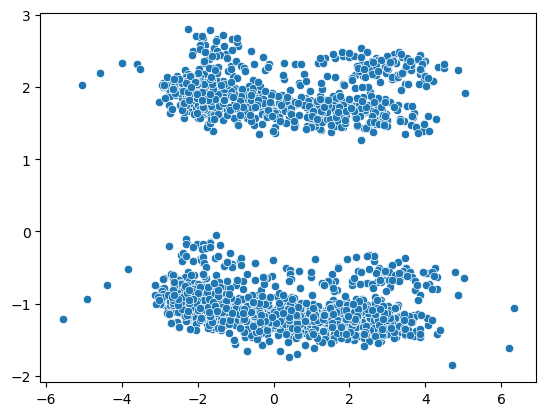

In [44]:

sns.scatterplot(
    x=X_pca[:,0], # PC1
    y=X_pca[:,1] # PC2
)

In [45]:

pca.explained_variance_ratio_

array([0.23163158, 0.11385454])

The first two principal components explain about **23%** and **11%** of the variance, or **34%** combined. We also inspect three components to capture more variance.

The 2D plot captures only 34% of the variance, so the 3D plot provides an additional view using the first three components.

### 3D PCA visualization

In [46]:
pca = PCA(
    n_components = 3
)

X_pca = pca.fit_transform(X_scaled)

In [47]:

pca.explained_variance_ratio_

array([0.23163158, 0.11385454, 0.10405815])

The first three principal components explain approximately **44%** of the variance. This helps visualization, but more than half of the variance remains outside the 3D view.

Text(0.5, 0.92, '3D Projection of dataset with PCA')

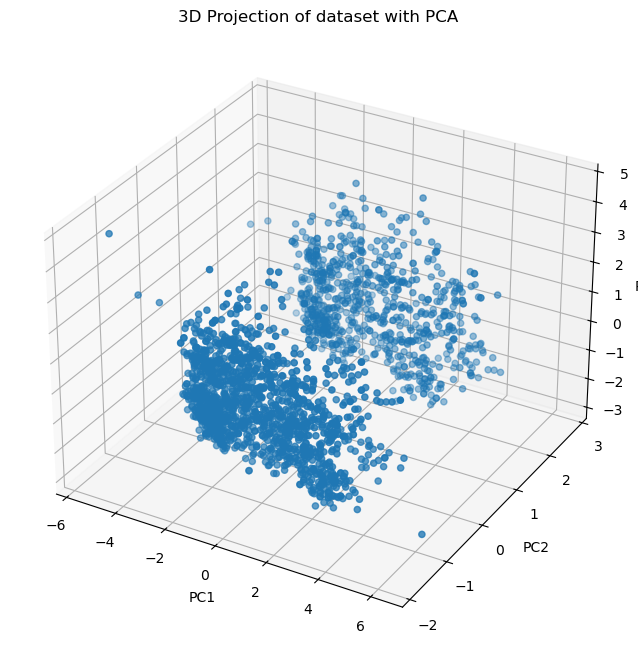

In [48]:
fig = plt.figure(figsize=(12,8))

ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2])

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("3D Projection of dataset with PCA")

Compare K-Means and Agglomerative Clustering, then inspect their cluster visualizations.

##### 9. Select the number of clusters

###### Elbow method

In [49]:
from sklearn.cluster import KMeans
from kneed import KneeLocator


In [50]:
wcss = []

for k in range(1,11):
    kmeans = KMeans(n_clusters=k, random_state = 42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

<Axes: >

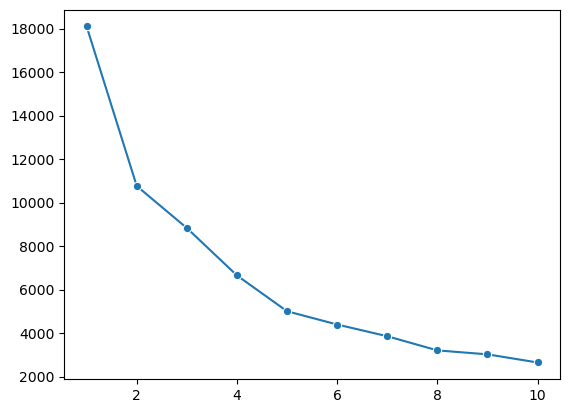

In [51]:
sns.lineplot(x= range(1,11), y= wcss, marker = "o")

In [52]:
from kneed import KneeLocator

knee = KneeLocator(
    range(1,11),
    wcss,
    curve = "convex",
    direction = "decreasing"
)
print("Optimal K value:", knee.elbow)

Optimal K value: 4


###### Silhouette score

In [53]:
from sklearn.metrics import silhouette_score

ss = []

for k in range(2,11):
    kmeans = KMeans(n_clusters = k , random_state=42)
    labels = kmeans.fit_predict(X_pca)
    score = silhouette_score(X_pca, labels)
    ss.append(score)

<Axes: >

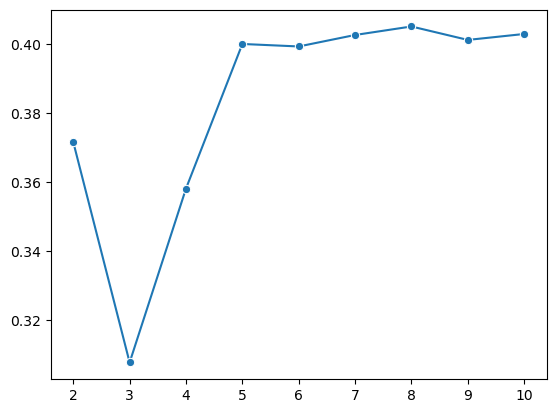

In [54]:
sns.lineplot(x= range(2,11), y = ss, marker ="o")

Use the elbow plot and silhouette score together to choose a reasonable number of clusters. The highest silhouette score is not the only consideration.

The intersection of WCSS and silhouette-score lines is only a visual clue because the metrics use different scales. Also consider the elbow shape and silhouette values.

Text(0, 0.5, 'Silhouette Score')

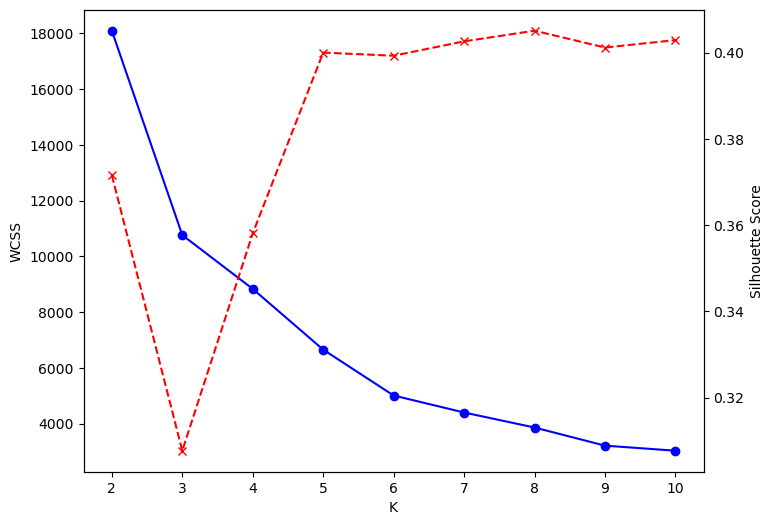

In [55]:
# Compare WCSS and Silhouette Score

k_range = range(2,11)

fig, ax1 = plt.subplots(figsize=(8,6))

ax1.plot(k_range, wcss[:len(k_range)], marker = "o", color = "blue")
ax1.set_xlabel("K")
ax1.set_ylabel("WCSS")

ax2 = ax1.twinx()
ax2.plot(k_range, ss[:len(k_range)], marker = "x", color="red", linestyle="--" )
ax2.set_ylabel("Silhouette Score")

The combined plot suggests **K = 4** as a practical choice for further analysis, based on the elbow and silhouette plots.

##### 10. Clustering

###### K-Means clustering

In [56]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters = 4,
    random_state = 42
)

labels_kmeans = kmeans.fit_predict(X_pca)

In [60]:
labels_kmeans

array([2, 3, 2, ..., 2, 1, 1], shape=(2236,), dtype=int32)

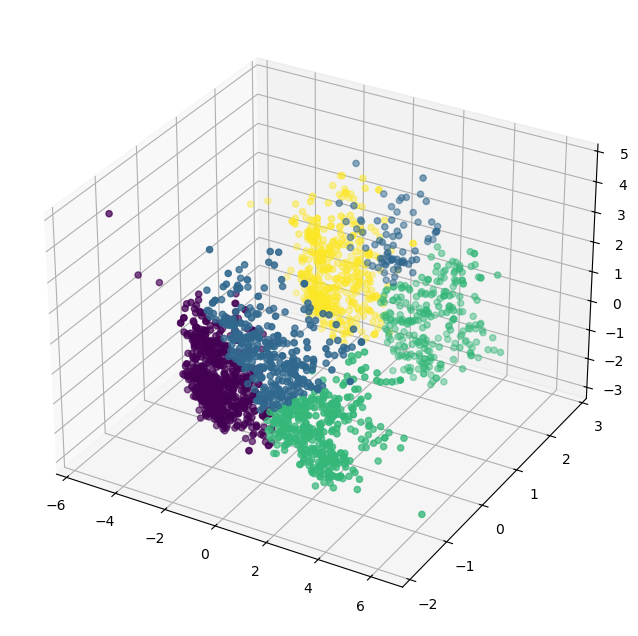

In [57]:
fig = plt.figure(figsize=(12,8))
ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c= labels_kmeans)

K-Means forms four clusters, although some overlap is visible in the PCA visualization.

###### Agglomerative clustering

In [58]:
from sklearn.cluster import AgglomerativeClustering

aggclus = AgglomerativeClustering(
    n_clusters = 4,
    linkage = "ward"
)

labels_agg = aggclus.fit_predict(X_pca)

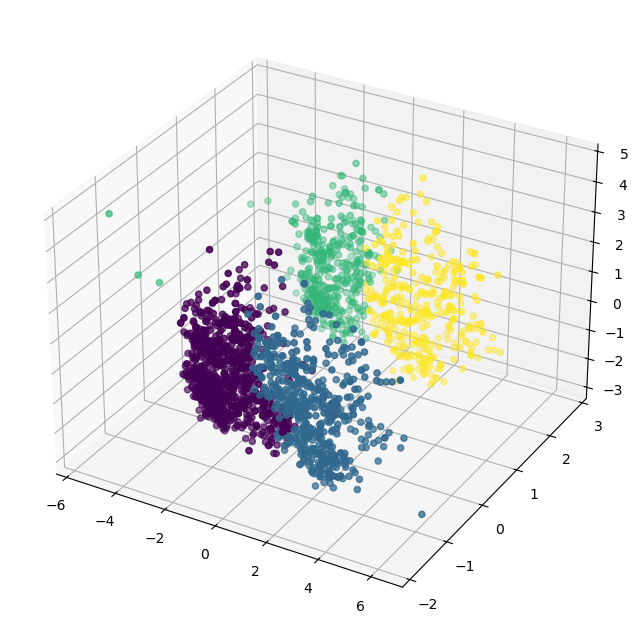

In [59]:
fig = plt.figure(figsize=(12,8))
ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c= labels_agg)

Agglomerative Clustering appears to show clearer separation in the visualization, so its labels are used for the following customer-profile analysis.

##### 11. Cluster characterization

Analyze each cluster to understand its customer profile and identify patterns that may support marketing decisions.

Add the Agglomerative Clustering labels (`labels_agg`) to `df_cleaned` for cluster-level analysis.

In [66]:
X["Cluster"] = labels_agg


In [67]:
X.head() 

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner,Cluster
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


Visualize the number of customers and compare key features across clusters.

<Axes: xlabel='Cluster', ylabel='count'>

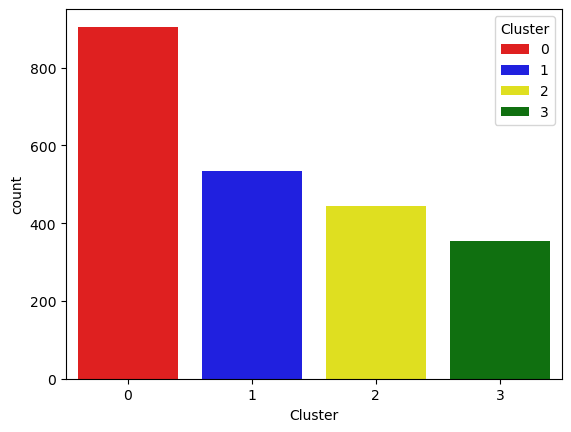

In [68]:
# Count customers in each cluster
pal = ["red", "blue", "yellow", "green"]

sns.countplot(x=X["Cluster"], palette= pal, hue = X["Cluster"])

Cluster 0 (red) contains the most customers, followed by Cluster 1 (blue), Cluster 2 (yellow), and Cluster 3 (green).

Compare `Income` and `Total_Spending`, which have a strong positive correlation in the heatmap, to profile the clusters.

<Axes: xlabel='Total_Spending', ylabel='Income'>

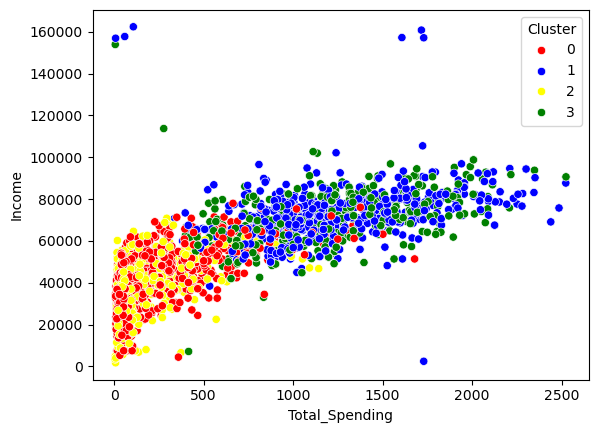

In [69]:
# Compare income and spending by cluster

sns.scatterplot(
    x = X["Total_Spending"],
    y = X["Income"],
    hue = X["Cluster"],
    palette = pal
)

### Customer profiles by income and spending

- **Cluster 0 (red):** Low-to-moderate income and spending.
- **Cluster 1 (blue):** High income and high spending.
- **Cluster 2 (yellow):** Low income and low spending.
- **Cluster 3 (green):** Moderate-to-high income and high spending.

**Summary:** Clusters 1 and 3 contain higher-income, higher-spending customers. Clusters 0 and 2 contain lower-income, lower-spending customers.

Compare household size, age, campaign response, living situation, and purchasing channels to understand additional differences between clusters.

##### Cluster summary

In [71]:

cluster_summary = X.groupby("Cluster").mean()
print(cluster_summary)


               Income    Recency  NumDealsPurchases  NumWebPurchases  \
Cluster                                                                
0        39680.580110  48.914917           2.594475         3.153591   
1        72808.445693  49.202247           1.958801         5.687266   
2        36960.143018  48.319820           2.594595         2.713964   
3        70722.681303  50.504249           1.855524         5.790368   

         NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
Cluster                                                                        
0                   0.969061           4.143646           6.307182  0.011050   
1                   5.498127           8.659176           3.580524  0.005618   
2                   0.837838           3.623874           6.659910  0.011261   
3                   5.014164           8.430595           3.728045  0.005666   

         Response        Age  Customer_Tenure_Days  Total_Spending  \
Cluster         

The cluster means support the income-and-spending patterns above. Clusters 1 and 3 can be treated as higher-spending segments, while Clusters 0 and 2 are lower-spending segments. These are descriptive profiles, not confirmed customer-value labels.

## Cluster characterization: key insights

- **Recency:** Values are broadly similar across clusters.
- **Children:** Clusters 0 and 2 have more children on average than Clusters 1 and 3. In this dataset, clusters with fewer children tend to spend more; this is an observed pattern, not proof of cause.
- **Age and income:** Clusters 1 and 3 are slightly older on average and have higher incomes.
- **Campaign response:** Cluster 3 has the strongest response, Clusters 1 and 2 are moderate, and Cluster 0 is lowest.
- **Living situation:** Clusters 0 and 1 have more customers categorized as `Partner`, while Clusters 2 and 3 have more categorized as `Alone`.
- **Website visits:** Clusters 0 and 2 visit the website more often; Clusters 1 and 3 visit less often.
- **Store and catalog purchases:** Clusters 1 and 3 make more purchases through these channels.

**Marketing insight:** Consider testing catalog, in-store, or other targeted campaigns for higher-spending customers who visit the website less often.